In [3]:
import pandas as pd
import numpy as np
import re
import ast
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler

RELATIVE_FEATURES_DIR = '../../data/features'
LANGUAGES = [                               # Languages to consider
    'ar',
    'de',
    'en',
    'es',
    'ja',
    'pl',
    'ru',
    'sw',
    'tr',
    'uz',
    'yue',
    'zh-TW'
]
NO_OF_LANGUAGES = len(LANGUAGES)

In [4]:
def fix_array_format(arr_str):
    arr_str = re.sub(r"\s+", ",", arr_str.strip())
    arr_str = arr_str.replace("[,", "[").replace(",]", "]")
    return np.array(ast.literal_eval(arr_str))

def fix_list_values(df):
    list_columns = ['mfcc_mean', 'mfcc_var', 'spectral_contrast_mean', 'spectral_contrast_var', 'chroma_mean', 'chroma_var']
    for col in list_columns:
        features_df = df[col].apply(fix_array_format).apply(pd.Series)
        features_df.columns = [f'{col}_{i}' for i in range(features_df.shape[1])]
        df = pd.concat([df.drop(columns=[col]), features_df], axis=1)
    
    return df

In [44]:
# we need a dataset containing all the features of all languages, so array [x, 76] where x is the number of samples
all_languages_features = []
y = []

for language in LANGUAGES:
    file = Path(f'{RELATIVE_FEATURES_DIR}') / f'{language}_features.csv'
    scaler = StandardScaler()
    df = pd.read_csv(file)

    # select only male speakers
    df = df[df['gender'].str.startswith('male')]
    # filter out teens
    df = df[~df['age'].str.contains('teens', case=False)]
    # drop columns starting with zrc_
    df = df.loc[:, ~df.columns.str.startswith('zcr_')]
    df = df.iloc[:, 3:] # drop non-numeric columns
    df = fix_list_values(df)
    X = df.to_numpy(dtype=float)

    scaled_X = scaler.fit_transform(X)
    all_languages_features.append(scaled_X)
    y.extend([file.stem.split('_')[0]] * scaled_X.shape[0])
    
# merge all languages features into one array
all_languages_features = np.concatenate(all_languages_features, axis=0)

In [6]:
best_features = []

### RFE (recursive feature elimination)

In [7]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

all_languages_features_df = pd.DataFrame(all_languages_features)

imputer = SimpleImputer(strategy='mean')
all_languages_features_df = pd.DataFrame(imputer.fit_transform(all_languages_features_df))

model = LogisticRegression()

rfe = RFE(model, n_features_to_select=3)
fit = rfe.fit(all_languages_features_df, y)

selected_features = all_languages_features_df.columns[fit.support_]
selected_features = all_languages_features_df[selected_features]

In [8]:
print(selected_features)

              55        56        57
0       1.041847  1.627207  1.991438
1       0.487322  0.126369 -0.274110
2      -0.131183 -0.198555  0.473482
3      -0.058246  0.081338 -0.665096
4      -0.295008 -0.156682  0.267378
...          ...       ...       ...
936069 -0.107201 -0.266262  0.563256
936070 -0.545105 -0.145368  0.204931
936071  0.111281  0.023423  0.470816
936072 -0.310753  0.190253  1.249990
936073 -0.920570 -0.547499  0.452011

[936074 rows x 3 columns]


In [9]:
print(df.columns[55])
print(df.columns[56])
print(df.columns[57])

chroma_mean_5
chroma_mean_6
chroma_mean_7


In [10]:
best_features.append(df.columns[55])
best_features.append(df.columns[56])
best_features.append(df.columns[57])

### Wzajemna informacja (Mutual Information)

In [12]:
from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(all_languages_features, y)

In [13]:
print(np.argsort(mi_scores)[:3])

[58 45 34]


In [14]:
print(df.columns[58])
print(df.columns[45])
print(df.columns[34])

chroma_mean_8
spectral_contrast_var_2
mfcc_var_11


In [15]:
best_features.append(df.columns[58])
best_features.append(df.columns[45])
best_features.append(df.columns[34])

In [16]:
print(df.columns[np.argsort(mi_scores)])

Index(['chroma_mean_8', 'spectral_contrast_var_2', 'mfcc_var_11',
       'chroma_mean_9', 'chroma_mean_10', 'mfcc_mean_4', 'mfcc_mean_12',
       'chroma_var_8', 'spectral_contrast_mean_1', 'chroma_mean_11',
       'mfcc_var_12', 'chroma_var_9', 'chroma_mean_7', 'mfcc_var_10',
       'chroma_var_10', 'mfcc_var_8', 'chroma_var_7',
       'spectral_contrast_mean_3', 'chroma_var_1', 'spectral_contrast_var_4',
       'spectral_contrast_var_3', 'chroma_var_0', 'chroma_mean_0',
       'mfcc_mean_10', 'chroma_mean_1', 'mfcc_var_4', 'mfcc_mean_6',
       'mfcc_mean_1', 'mfcc_var_3', 'chroma_mean_6', 'spectral_contrast_var_5',
       'mfcc_mean_11', 'chroma_var_6', 'mfcc_mean_8', 'mfcc_var_6',
       'mfcc_var_5', 'mfcc_var_9', 'spectral_contrast_var_1', 'mfcc_var_7',
       'chroma_var_3', 'chroma_var_4', 'chroma_var_2', 'mfcc_mean_2',
       'chroma_var_11', 'spectral_contrast_var_0', 'spectral_contrast_mean_2',
       'chroma_var_5', 'spectral_contrast_mean_4', 'chroma_mean_2',
       'mfcc_

### Feature Importance z modeli uczących się


#### Las losowy (Random Forest)

In [18]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
model.fit(all_languages_features, y)
importances = model.feature_importances_

In [19]:
print(np.argsort(importances)[:3])

[70 62 63]


In [20]:
print(df.columns[70])
print(df.columns[62])
print(df.columns[69])

chroma_var_8
chroma_var_0
chroma_var_7


In [21]:
best_features.append(df.columns[70])
best_features.append(df.columns[62])
best_features.append(df.columns[69])

In [22]:
print(df.columns[np.argsort(importances)])

Index(['chroma_var_8', 'chroma_var_0', 'chroma_var_1', 'mfcc_var_11',
       'chroma_var_7', 'spectral_contrast_var_3', 'chroma_var_10',
       'chroma_var_9', 'mfcc_var_12', 'chroma_mean_8', 'chroma_mean_7',
       'mfcc_var_10', 'chroma_mean_0', 'chroma_var_2', 'chroma_var_6',
       'mfcc_var_9', 'mfcc_var_8', 'chroma_var_4', 'spectral_contrast_var_2',
       'mfcc_var_4', 'chroma_mean_10', 'chroma_var_5', 'chroma_var_3',
       'chroma_var_11', 'chroma_mean_9', 'chroma_mean_11',
       'spectral_contrast_var_4', 'spectral_contrast_mean_3', 'mfcc_var_5',
       'chroma_mean_6', 'chroma_mean_1', 'mfcc_var_7', 'mfcc_mean_12',
       'spectral_contrast_var_1', 'spectral_contrast_var_5', 'mfcc_var_3',
       'spectral_contrast_mean_1', 'mfcc_mean_11', 'chroma_mean_4',
       'chroma_mean_5', 'mfcc_var_6', 'spectral_contrast_mean_2',
       'chroma_mean_3', 'spectral_contrast_mean_4', 'mfcc_mean_10',
       'spectral_contrast_mean_5', 'chroma_mean_2', 'mfcc_mean_4',
       'mfcc_mean_8',

#### Gradient Boosting 

In [24]:
from xgboost import XGBClassifier
y_numeric = [LANGUAGES.index(language) for language in y]
model = XGBClassifier()
model.fit(all_languages_features, y_numeric)
importances_xgboost = model.feature_importances_

In [25]:
print(np.argsort(importances_xgboost)[:3])

[63 70 34]


In [26]:
print(df.columns[63])
print(df.columns[70])
print(df.columns[34])

chroma_var_1
chroma_var_8
mfcc_var_11


In [27]:
best_features.append(df.columns[63])
best_features.append(df.columns[70])
best_features.append(df.columns[34])

In [29]:
print(df.columns[np.argsort(importances_xgboost)])

Index(['chroma_var_1', 'chroma_var_8', 'mfcc_var_11',
       'spectral_contrast_var_3', 'chroma_var_7', 'chroma_var_9',
       'chroma_var_10', 'mfcc_var_10', 'chroma_var_3', 'chroma_var_2',
       'chroma_var_0', 'chroma_mean_7', 'chroma_var_6', 'mfcc_var_8',
       'chroma_var_4', 'chroma_var_5', 'chroma_mean_8', 'chroma_mean_11',
       'spectral_contrast_var_2', 'mfcc_var_7', 'chroma_mean_6', 'mfcc_var_12',
       'chroma_mean_1', 'spectral_contrast_var_4', 'chroma_var_11',
       'chroma_mean_9', 'mfcc_var_4', 'spectral_contrast_mean_3', 'mfcc_var_9',
       'spectral_contrast_mean_1', 'mfcc_mean_2', 'mfcc_var_5',
       'spectral_contrast_var_5', 'chroma_mean_4', 'spectral_contrast_mean_5',
       'spectral_contrast_var_1', 'chroma_mean_10', 'spectral_centroid_var',
       'spectral_contrast_mean_2', 'mfcc_mean_8', 'mfcc_mean_4',
       'mfcc_mean_11', 'chroma_mean_3', 'mfcc_mean_12', 'chroma_mean_5',
       'chroma_mean_2', 'spectral_centroid_mean', 'mfcc_mean_10',
       'spect

###  Selekcja cech oparta na L1 (LASSO)

In [31]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(penalty='l1', solver='liblinear')
model.fit(all_languages_features, y)
importance_lasso = model.coef_

In [32]:
print(np.argsort(importance_lasso)[0][:3])

[ 0 52 51]


In [33]:
best_features.append(df.columns[0])
best_features.append(df.columns[52])
best_features.append(df.columns[51])

In [34]:
print(df.columns[np.argsort(importance_lasso)[0]])

Index(['pitch_mean', 'chroma_mean_2', 'chroma_mean_1', 'chroma_mean_0',
       'spectral_contrast_var_6', 'spectral_contrast_var_5',
       'spectral_contrast_var_4', 'chroma_mean_3', 'spectral_contrast_var_3',
       'spectral_contrast_var_1', 'spectral_contrast_var_0',
       'spectral_contrast_mean_6', 'spectral_contrast_mean_5',
       'spectral_contrast_mean_4', 'spectral_contrast_mean_3',
       'spectral_contrast_var_2', 'chroma_mean_4', 'chroma_mean_5',
       'chroma_mean_6', 'chroma_var_9', 'chroma_var_8', 'chroma_var_7',
       'chroma_var_6', 'chroma_var_5', 'chroma_var_4', 'chroma_var_3',
       'chroma_var_2', 'chroma_var_1', 'chroma_var_0', 'chroma_mean_11',
       'chroma_mean_10', 'chroma_mean_9', 'chroma_mean_8', 'chroma_mean_7',
       'spectral_contrast_mean_2', 'spectral_contrast_mean_1',
       'spectral_contrast_mean_0', 'mfcc_var_12', 'mfcc_mean_5', 'mfcc_mean_4',
       'mfcc_mean_3', 'mfcc_mean_2', 'mfcc_mean_1', 'mfcc_mean_0',
       'spectral_flatness_var', 

### Analiza komponentów liniowych

In [36]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis()
lda.fit(all_languages_features, y)

LinearDiscriminantAnalysis()

In [37]:
lda_coefficients = lda.coef_
feature_importance = np.linalg.norm(lda_coefficients, axis=0)
feature_ranking = np.argsort(feature_importance)[::-1]  # Indeksy cech od najbardziej do najmniej istotnych
ranked_features = [df.columns[i] for i in feature_ranking]

In [38]:
print(ranked_features)

['chroma_mean_5', 'chroma_mean_6', 'chroma_mean_4', 'chroma_mean_3', 'chroma_mean_9', 'chroma_mean_10', 'chroma_mean_7', 'chroma_mean_0', 'chroma_mean_11', 'chroma_mean_1', 'chroma_mean_2', 'chroma_mean_8', 'spectral_bandwidth_mean', 'chroma_var_5', 'chroma_var_6', 'spectral_centroid_mean', 'chroma_var_4', 'chroma_var_0', 'chroma_var_9', 'chroma_var_10', 'chroma_var_3', 'spectral_contrast_mean_6', 'chroma_var_1', 'chroma_var_11', 'chroma_var_7', 'chroma_var_2', 'mfcc_var_1', 'spectral_contrast_mean_3', 'spectral_bandwidth_var', 'spectral_contrast_mean_1', 'chroma_var_8', 'spectral_flatness_mean', 'pitch_mean', 'mfcc_var_0', 'pitch_var', 'spectral_contrast_mean_4', 'spectral_flatness_var', 'spectral_contrast_mean_2', 'spectral_centroid_var', 'mfcc_mean_5', 'spectral_contrast_var_3', 'spectral_contrast_mean_5', 'mfcc_mean_3', 'spectral_contrast_var_6', 'mfcc_mean_2', 'spectral_contrast_var_1', 'mfcc_mean_1', 'spectral_contrast_var_4', 'mfcc_mean_6', 'mfcc_var_2', 'mfcc_mean_0', 'mfcc_var

In [39]:
best_features.append(ranked_features[0])
best_features.append(ranked_features[1])
best_features.append(ranked_features[2])

## Clusterization

In [72]:
from collections import Counter
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

feature_counts = Counter(best_features)

# Select top 5 features
top_features = [feature for feature, count in feature_counts.most_common(5)]

print(f'Top 5 selected features from above feature selection methods: {top_features}')

Top 5 selected features from above feature selection methods: ['chroma_mean_5', 'chroma_mean_6', 'mfcc_var_11', 'chroma_var_8', 'chroma_mean_7']


In [105]:
column_names = ['pitch_mean', 'pitch_var', 'hnr_mean', 'hnr_var',
                'spectral_centroid_mean', 'spectral_centroid_var',
                'spectral_bandwidth_mean', 'spectral_bandwidth_var',
                'spectral_flatness_mean', 'spectral_flatness_var', 'mfcc_mean_0',
                'mfcc_mean_1', 'mfcc_mean_2', 'mfcc_mean_3', 'mfcc_mean_4',
                'mfcc_mean_5', 'mfcc_mean_6', 'mfcc_mean_7', 'mfcc_mean_8',
                'mfcc_mean_9', 'mfcc_mean_10', 'mfcc_mean_11', 'mfcc_mean_12',
                'mfcc_var_0', 'mfcc_var_1', 'mfcc_var_2', 'mfcc_var_3', 'mfcc_var_4',
                'mfcc_var_5', 'mfcc_var_6', 'mfcc_var_7', 'mfcc_var_8', 'mfcc_var_9',
                'mfcc_var_10', 'mfcc_var_11', 'mfcc_var_12', 'spectral_contrast_mean_0',
                'spectral_contrast_mean_1', 'spectral_contrast_mean_2',
                'spectral_contrast_mean_3', 'spectral_contrast_mean_4',
                'spectral_contrast_mean_5', 'spectral_contrast_mean_6',
                'spectral_contrast_var_0', 'spectral_contrast_var_1',
                'spectral_contrast_var_2', 'spectral_contrast_var_3',
                'spectral_contrast_var_4', 'spectral_contrast_var_5',
                'spectral_contrast_var_6', 'chroma_mean_0', 'chroma_mean_1',
                'chroma_mean_2', 'chroma_mean_3', 'chroma_mean_4', 'chroma_mean_5',
                'chroma_mean_6', 'chroma_mean_7', 'chroma_mean_8', 'chroma_mean_9',
                'chroma_mean_10', 'chroma_mean_11', 'chroma_var_0', 'chroma_var_1',
                'chroma_var_2', 'chroma_var_3', 'chroma_var_4', 'chroma_var_5',
                'chroma_var_6', 'chroma_var_7', 'chroma_var_8', 'chroma_var_9',
                'chroma_var_10', 'chroma_var_11']

assert len(column_names) == all_languages_features.shape[1], "Column names length does not match number of columns in the numpy array"

df = pd.DataFrame(all_languages_features, columns=column_names)

In [123]:
scores = dict()

for feature in column_names:
    if feature in df.columns:
        X = df[[feature]].values
        
        # Perform KMeans clustering
        kmeans = KMeans(n_clusters=NO_OF_LANGUAGES, random_state=42, n_init=100)
        labels = kmeans.fit_predict(X)

        # Map cluster labels to the most common true label in each cluster
        mapped_labels = np.empty_like(labels, dtype=object)
        for cluster_label in np.unique(labels):
            cluster_indices = np.where(labels == cluster_label)[0]
            cluster_languages = [y[i] for i in cluster_indices]
            most_common_language = Counter(cluster_languages).most_common(1)[0][0]
            for i in cluster_indices:
                mapped_labels[i] = most_common_language

        # Compare clustering labels with actual labels using ARI and NMI
        ari = adjusted_rand_score(y, labels)
        nmi = normalized_mutual_info_score(y, labels)
        
        # Store scores in dictionary
        scores = dict(scores, **{
            feature: {
                'ari': ari,
                'nmi': nmi
            }
        })
    else:
        print(f'Feature {feature} not found in the dataset')

# Print scores for each feature
for feature, metrics in scores.items():
    print(f"Feature: {feature}, ARI: {metrics['ari']:.4f}, NMI: {metrics['nmi']:.4f}")


Feature: pitch_mean, ARI: 0.0970, NMI: 0.1210
Feature: pitch_var, ARI: 0.1673, NMI: 0.1618
Feature: hnr_mean, ARI: 0.0259, NMI: 0.0433
Feature: hnr_var, ARI: 0.0370, NMI: 0.0453
Feature: spectral_centroid_mean, ARI: 0.0018, NMI: 0.0063
Feature: spectral_centroid_var, ARI: -0.0000, NMI: 0.0084
Feature: spectral_bandwidth_mean, ARI: 0.0067, NMI: 0.0185
Feature: spectral_bandwidth_var, ARI: 0.0068, NMI: 0.0209
Feature: spectral_flatness_mean, ARI: 0.0022, NMI: 0.0130
Feature: spectral_flatness_var, ARI: 0.1448, NMI: 0.2897
Feature: mfcc_mean_0, ARI: 0.0037, NMI: 0.0061
Feature: mfcc_mean_1, ARI: 0.0004, NMI: 0.0021
Feature: mfcc_mean_2, ARI: 0.0025, NMI: 0.0033
Feature: mfcc_mean_3, ARI: 0.0033, NMI: 0.0056
Feature: mfcc_mean_4, ARI: 0.0000, NMI: 0.0013
Feature: mfcc_mean_5, ARI: 0.0038, NMI: 0.0069
Feature: mfcc_mean_6, ARI: 0.0011, NMI: 0.0021
Feature: mfcc_mean_7, ARI: 0.0032, NMI: 0.0076
Feature: mfcc_mean_8, ARI: 0.0014, NMI: 0.0025
Feature: mfcc_mean_9, ARI: 0.0015, NMI: 0.0041
Feat

In [125]:
#sort scores by two values first ari and second nmi
print(sorted(scores.items(), key=lambda x: (x[1]['ari'], x[1]['nmi']), reverse=True))

[('pitch_var', {'ari': 0.16730149220869053, 'nmi': 0.1618474030072375}), ('spectral_flatness_var', {'ari': 0.14478379226570023, 'nmi': 0.2896773206872067}), ('pitch_mean', {'ari': 0.09702146492207493, 'nmi': 0.12104462166821009}), ('hnr_var', {'ari': 0.03696048842735997, 'nmi': 0.0453342123860544}), ('spectral_contrast_var_6', {'ari': 0.028244449845151953, 'nmi': 0.04116697465947812}), ('hnr_mean', {'ari': 0.025946380835024405, 'nmi': 0.04325179685832458}), ('spectral_bandwidth_var', {'ari': 0.006849253040040138, 'nmi': 0.02086681714606016}), ('spectral_bandwidth_mean', {'ari': 0.006719393490248014, 'nmi': 0.018499198606483996}), ('spectral_contrast_mean_6', {'ari': 0.004200429280847454, 'nmi': 0.008175389874774106}), ('spectral_contrast_mean_5', {'ari': 0.004180768086322347, 'nmi': 0.004221488781996671}), ('mfcc_var_1', {'ari': 0.0038704161386502968, 'nmi': 0.008356823695908597}), ('mfcc_mean_5', {'ari': 0.0037682365589459268, 'nmi': 0.006917445126957768}), ('mfcc_mean_0', {'ari': 0.0

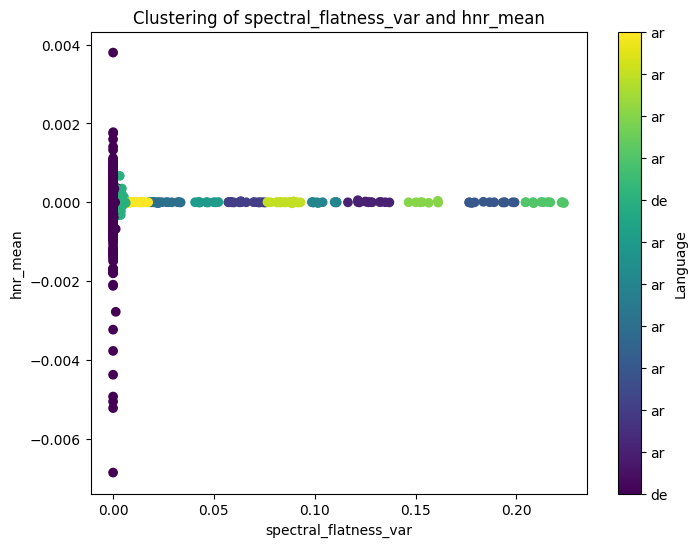

In [69]:
features_to_cluster = ['spectral_flatness_var', 'hnr_mean']

if all(feature in df.columns for feature in features_to_cluster):
    X = df[features_to_cluster].values
    
    kmeans = KMeans(n_clusters=12, random_state=42, n_init=100)
    labels = kmeans.fit_predict(X)
    
    # Map cluster labels to the most common language abbreviation in each cluster
    language_mapping = {}
    for cluster_label in np.unique(labels):
        cluster_indices = np.where(labels == cluster_label)[0]
        cluster_languages = [y[i] for i in cluster_indices]
        most_common_language = Counter(cluster_languages).most_common(1)[0][0]
        language_mapping[cluster_label] = most_common_language
    
    # Plot the clusters
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
    plt.title('Clustering of spectral_flatness_var and hnr_mean')
    plt.xlabel('spectral_flatness_var')
    plt.ylabel('hnr_mean')
    
    # Create a color bar with language abbreviations
    cbar = plt.colorbar(scatter, ticks=np.arange(12))
    cbar.set_label('Language')
    cbar.set_ticks(np.arange(12))
    cbar.set_ticklabels([language_mapping[i] for i in range(12)])
    
    plt.savefig('../../data/plots/spectral_flatness_var_hnr_mean_clustering.png')
    plt.show()
else:
    print('One or both features not found in the dataset')

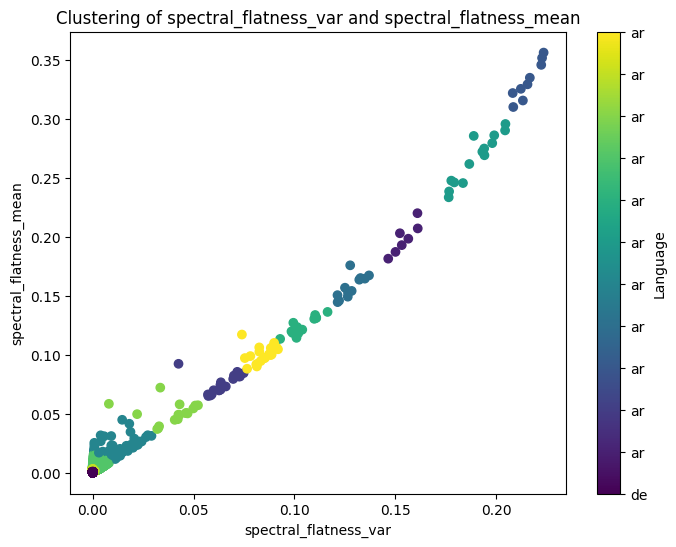

In [70]:
features_to_cluster = ['spectral_flatness_var', 'spectral_flatness_mean']

if all(feature in df.columns for feature in features_to_cluster):
    X = df[features_to_cluster].values
    
    kmeans = KMeans(n_clusters=12, random_state=42, n_init=100)
    labels = kmeans.fit_predict(X)
    
    # Map cluster labels to the most common language abbreviation in each cluster
    language_mapping = {}
    for cluster_label in np.unique(labels):
        cluster_indices = np.where(labels == cluster_label)[0]
        cluster_languages = [y[i] for i in cluster_indices]
        most_common_language = Counter(cluster_languages).most_common(1)[0][0]
        language_mapping[cluster_label] = most_common_language
    
    # Plot the clusters
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
    plt.title('Clustering of spectral_flatness_var and spectral_flatness_mean')
    plt.xlabel('spectral_flatness_var')
    plt.ylabel('spectral_flatness_mean')
    
    # Create a color bar with language abbreviations
    cbar = plt.colorbar(scatter, ticks=np.arange(12))
    cbar.set_label('Language')
    cbar.set_ticks(np.arange(12))
    cbar.set_ticklabels([language_mapping[i] for i in range(12)])
    
    plt.savefig('../../data/plots/spectral_flatness_var_spectral_flatness_mean_clustering.png')
    plt.show()
else:
    print('One or both features not found in the dataset')

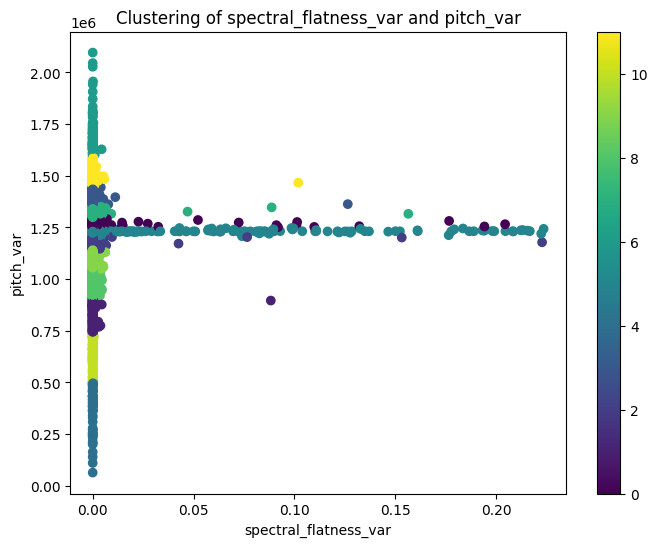

In [64]:
features_to_cluster = ['spectral_flatness_var', 'pitch_var']

if all(feature in df.columns for feature in features_to_cluster):
    X = df[features_to_cluster].values
    
    kmeans = KMeans(n_clusters=12, random_state=42, n_init=100)
    labels = kmeans.fit_predict(X)
    
    # Plot the clusters
    plt.figure(figsize=(8, 6))
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
    plt.title('Clustering of spectral_flatness_var and pitch_var')
    plt.xlabel('spectral_flatness_var')
    plt.ylabel('pitch_var')
    plt.colorbar()
    plt.savefig('../../data/plots/spectral_flatness_var_pitch_var_clustering.png')
    plt.show()
else:
    print('One or both features not found in the dataset')

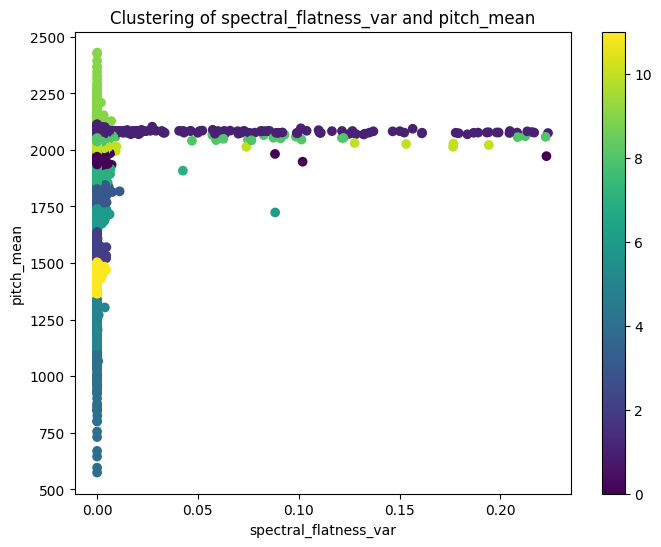

In [65]:
features_to_cluster = ['spectral_flatness_var', 'pitch_mean']

if all(feature in df.columns for feature in features_to_cluster):
    X = df[features_to_cluster].values
    
    kmeans = KMeans(n_clusters=12, random_state=42, n_init=100)
    labels = kmeans.fit_predict(X)
    
    # Plot the clusters
    plt.figure(figsize=(8, 6))
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
    plt.title('Clustering of spectral_flatness_var and pitch_mean')
    plt.xlabel('spectral_flatness_var')
    plt.ylabel('pitch_mean')
    plt.colorbar()
    plt.savefig('../../data/plots/spectral_flatness_var_pitch_mean_clustering.png')
    plt.show()
else:
    print('One or both features not found in the dataset')